In [29]:
###############################################################################################################################################################
# Author: Brandy Wilkinson
#         DSA 405
#         Fall 2026
#
# Description:
#         This script `02_analysis_and_figures.ipynb`loads the validated dataset
#         from `01_extraction_and_verification.ipynb` to perform exploratory statistical analysis and generate comparative visualizations of glyphosate
#         residues against federal EPA MRLs (40 CFR 180.364). It aggregates sample distributions, peak concentrations, and MRL utilization ratios across
#         Soybeans (n = 829) and Corn n = 219) to produce the final figures and summary tables for the presentation.
#
#
#
# Issues:
#        No issues detected
# ###############################################################################################################################################################

In [30]:
import pandas as pd

# URL for dataset (generated in 01_extraction_and_verification.ipynb) used for this notebvook
GITHUB_CSV_URL = "https://raw.githubusercontent.com/brandywii/dsa405-project/main/data/raw/merged_glyphosate_data.csv"

# Load the cleaned, validated dataset exported by 01_extraction_and_verification.ipynb
merged_df = pd.read_csv(GITHUB_CSV_URL)

In [31]:

merged_df["Pct_of_MRL"] = (merged_df["Concentration"] / merged_df["EPA_Tolerance_Limit"]) * 100

# Summary statistics grouped by commodity -> For P4 Report and Lightning talk slides
summary_stats = (
    merged_df.groupby(["Commod", "Commodity", "Is_GMO", "EPA_Tolerance_Limit"], as_index=False)
    .agg(
        Total_Samples=("Concentration", "count"),
        Mean_ppm=("Concentration", "mean"),
        Median_ppm=("Concentration", "median"),
        Min_ppm=("Concentration", "min"),
        Max_ppm=("Concentration", "max"),
        Std_ppm=("Concentration", "std"),
        Max_Pct_of_MRL=("Pct_of_MRL", "max")
    )
)

summary_stats

,Commod,Commodity,Is_GMO,EPA_Tolerance_Limit,Total_Samples,Mean_ppm,Median_ppm,Min_ppm,Max_ppm,Std_ppm,Max_Pct_of_MRL
0,CO,"Corn, field, grain",True,5.0,219,0.054037,0.050,0.05,0.136,0.010693,2.720
1,SY,"Soybean, seed",True,20.0,829,1.221083,0.782,0.10,18.525,1.534793,92.625


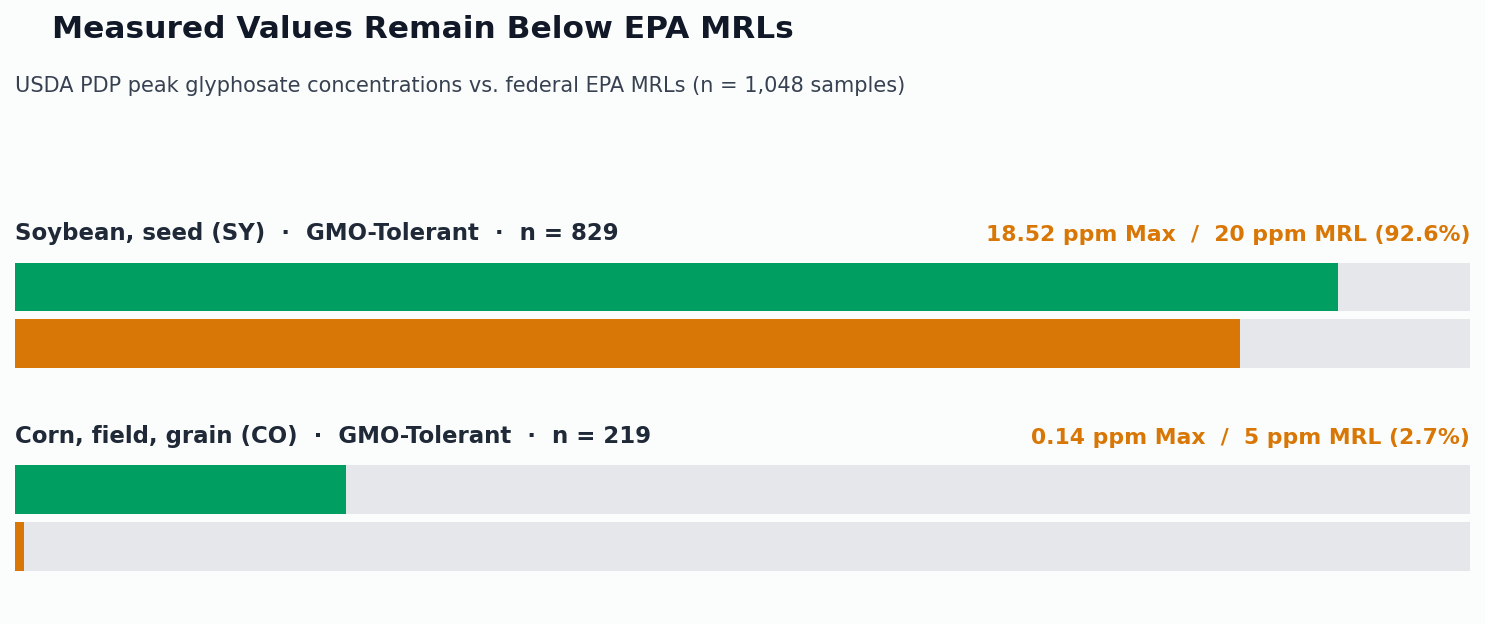

In [35]:
from pathlib import Path
import matplotlib.pyplot as plt

# Create local figures folder in Colab
FIG_DIR = Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 4.2), dpi=150)
fig.patch.set_facecolor("#FAFDFB")
ax.set_facecolor("#FAFDFB")

plot_df = summary_stats.sort_values(by="Max_ppm", ascending=True).reset_index(drop=True)
max_x = 22.0

for idx, row in plot_df.iterrows():
    trait = "GMO-Tolerant" if row["Is_GMO"] else "Standard"
    ax.barh(idx + 0.14, max_x, height=0.24, color="#E5E7EB")
    ax.barh(idx - 0.14, max_x, height=0.24, color="#E5E7EB")
    ax.barh(idx + 0.14, row["EPA_Tolerance_Limit"], height=0.24, color="#009E60")
    ax.barh(idx - 0.14, row["Max_ppm"], height=0.24, color="#D97706")

    ax.text(
        0, idx + 0.35,
        f"{row['Commodity']} ({row['Commod']})  ·  {trait}  ·  n = {row['Total_Samples']}",
        fontsize=11, fontweight="bold", color="#1F2937", va="bottom", ha="left"
    )
    ax.text(
        max_x, idx + 0.35,
        f"{row['Max_ppm']:.2f} ppm Max  /  {row['EPA_Tolerance_Limit']:.0f} ppm MRL ({row['Max_Pct_of_MRL']:.1f}%)",
        fontsize=10.5, fontweight="bold", color="#D97706", va="bottom", ha="right"
    )

plt.suptitle("Measured Values Remain Below EPA MRLs", x=0.04, y=0.98, ha="left", fontsize=15, fontweight="bold", color="#111827")
ax.set_title("USDA PDP peak glyphosate concentrations vs. federal EPA MRLs (n = 1,048 samples)", loc="left", fontsize=10, color="#374151", pad=20)
ax.set_xlim(0, max_x)
ax.set_ylim(-0.45, len(plot_df) - 0.1)
ax.axis("off")

plt.tight_layout()

# Save high-res figure locally
plt.savefig(FIG_DIR / "fig1_pdp_measured_vs_mrl.png", bbox_inches="tight", dpi=300)
plt.show()